# Student Grade Prediction model
Research Question: É possível prever as notas de alunos a partir de dados socioeconômicos?
Business Question: Quais segmentos de alunos devem ser endereçados com políticas de permanência que tenham como foco aumentar o rendimento acadêmico?

O estudo irá endereçar aspectos em 4 frentes: características dos alunos; estrutura familiar; inclusão tecnológica e situação escolar. O objetivo é abordar o potencial de políticas de inclusão e permanência no rendimento acadêmico de alunos com baixo status socioeconômico.

In [25]:
# loading libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('student_grade_ses_dataset.csv', sep=',')  # Carregando o dataset de notas dos alunos
df.head()  # Exibindo as primeiras linhas do DataFrame

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


Vamos começar por uma etapa de análise exploratória, fundamental para conhecer a distribuição dos dados e estabelecer testes de hipóteses

## Variáveis presentes no banco
O banco possui as seguintes variáveis:
- `student_id`: identificador único do aluno.
- `academic_year`: ano letivo.
- `survey_date`: data da coleta dos dados.
- `age`: idade do aluno.
- `gender`: gênero do aluno.
- `grade_level`: série escolar.
- `school_type`: tipo de escola.
- `residence_type`: área de residência, urbana ou rural.
- `family_size`: número de pessoas na família.
- `num_siblings`: número de irmãos.
- `single_parent_household`: indica se o aluno vive em família monoparental.
- `family_income_bracket`: faixa de renda familiar.
- `annual_family_income_inr`: renda familiar anual em rúpias indianas.
- `father_education_level`: nível de escolaridade do pai.
- `mother_education_level`: nível de escolaridade da mãe.
- `father_occupation`: ocupação do pai.
- `mother_occupation`: ocupação da mãe.
- `has_internet_access`: indica se há acesso à internet.
- `has_computer_or_laptop`: indica se há computador ou notebook em casa.
- `distance_to_school_km`: distância até a escola, em quilômetros.
- `scholarship_status`: situação da bolsa de estudos.
- `extra_tutoring`: indica se o aluno recebe aulas de reforço.
- `parental_involvement_score`: pontuação de envolvimento dos responsáveis.
- `study_hours_per_week`: horas de estudo por semana.
- `attendance_rate_pct`: percentual de frequência escolar.
- `previous_year_grade_pct`: nota percentual do ano anterior.
- `final_grade_pct`: nota percentual final.
- `grade_class`: classificação da nota final.
- `at_risk_flag`: indica se o aluno está em situação de risco acadêmico.

## Quais são as variáveis de interesse?
- `final_grade_pct`: uma variável contínua que indica a nota percentual final de 0 a 100.
- `at_risk_flag`: uma variável dummy que indica situação de risco acadêmico.

## Quais são as variáveis preditoras?
As variáveis preditoras serão agrupadas da seguinte forma:

### Características dos alunos
- `gender`: gênero do aluno.
- `age`: idade do aluno.

## Estrutura familiar
- `distance_to_school_km`: distância até a escola, em quilômetros.
- `residence_type`: área de residência, urbana ou rural.
- `family_size`: número de pessoas na família.
- `family_income_bracket`: faixa de renda familiar.
- `single_parent_household`: indica se o aluno vive em família monoparental.
- `father_education_level`: nível de escolaridade do pai.
- `mother_education_level`: nível de escolaridade da mãe.
- `father_occupation`: ocupação do pai.
- `mother_occupation`: ocupação da mãe.
- `parental_involvement_score`: pontuação de envolvimento dos responsáveis.

## Inclusão tecnológica
- `has_internet_access`: indica se há acesso à internet.
- `has_computer_or_laptop`: indica se há computador ou notebook em casa.

## Situação escolar
- `school_type`: tipo de escola.
- `scholarship_status`: situação da bolsa de estudos.
- `extra_tutoring`: indica se o aluno recebe aulas de reforço.
- `study_hours_per_week`: horas de estudo por semana.
- `attendance_rate_pct`: percentual de frequência escolar.

## Quais são as hipóteses em relação a cada grupo de variáveis preditoras?
- Características dos alunos: relação de causalidade fraca entre gênero, idade e rendimento acadêmico.
- Estrutura familiar: relaçao de causalidade forte entre famílias de baixa renda, em zona rural, longe da escola, e com baixo envolvimento parental nos estudos e baixa escolaridade dos pais.
- Inclusão tecnológica: relação de causalidade fraca.
- Situação Escolar: relação de causalidade forte e que supera o potencial explicativo da estrutura familiar, ou seja, alunos que recebem apoio acadêmico na forma de reforços, bolsas e têm acesso a escolas de melhor qualidade, têm melhor rendimento acadêmico mesmo em famílias de baixo padrão socioeconômico, o que reforça a necessidade de implementar essas políticas.


# Etapa 1: Criação de um dicionário de dados
Vamos agrupar as variáveis de acordo com os grupos analíticos determinados e os tipos de dados para decidirmos as visualizações adequadas e modelos preditivos.

In [19]:
# criando as listas de grupos analíticos
grupos_analiticos = {
    "Características dos alunos": [
        "gender",
        "age"
    ],
    "Estrutura familiar": [
        "distance_to_school_km",
        "residence_type",
        "family_size",
        "family_income_bracket",
        "single_parent_household",
        "father_education_level",
        "mother_education_level",
        "father_occupation",
        "mother_occupation",
        "parental_involvement_score"
    ],
    "Inclusão tecnológica": [
        "has_internet_access",
        "has_computer_or_laptop"
    ],
    "Situação escolar": [
        "school_type",
        "scholarship_status",
        "extra_tutoring",
        "study_hours_per_week",
        "attendance_rate_pct"
    ]
}

print('Lista dos grupos analíticos com as variáveis correspondentes criada com sucesso!')
print(grupos_analiticos)

Lista dos grupos analíticos com as variáveis correspondentes criada com sucesso!
{'Características dos alunos': ['gender', 'age'], 'Estrutura familiar': ['distance_to_school_km', 'residence_type', 'family_size', 'family_income_bracket', 'single_parent_household', 'father_education_level', 'mother_education_level', 'father_occupation', 'mother_occupation', 'parental_involvement_score'], 'Inclusão tecnológica': ['has_internet_access', 'has_computer_or_laptop'], 'Situação escolar': ['school_type', 'scholarship_status', 'extra_tutoring', 'study_hours_per_week', 'attendance_rate_pct']}


In [20]:
# criando um dicionário de dados a partir dos grupos analíticos e do tipo de cada variável
#colocando o nome das oclunas numa lista
nomes_colunas = df.columns.tolist()

# Cria a lista onde iremos classificar as variáveis com o grupo analítico correspondente
linhas_metadados = []
for grupos_analiticos, nomes_colunas in grupos_analiticos.items():
    for var in nomes_colunas:
        #Se a variável existe no df, obter o tipo de dado
        if var in df:
            tipo = str(df[var].dtype)
        else:
            tipo = 'Não encontrado no DATAFRAME'
        linhas_metadados.append({
            'variavel': var,
            'grupo_analitico': grupos_analiticos,
            'tipo_dado': tipo
        })

df_dicionario = pd.DataFrame(linhas_metadados)
print(df_dicionario)

                      variavel             grupo_analitico tipo_dado
0                       gender  Características dos alunos       str
1                          age  Características dos alunos     int64
2        distance_to_school_km          Estrutura familiar   float64
3               residence_type          Estrutura familiar       str
4                  family_size          Estrutura familiar     int64
5        family_income_bracket          Estrutura familiar       str
6      single_parent_household          Estrutura familiar     int64
7       father_education_level          Estrutura familiar       str
8       mother_education_level          Estrutura familiar       str
9            father_occupation          Estrutura familiar       str
10           mother_occupation          Estrutura familiar       str
11  parental_involvement_score          Estrutura familiar     int64
12         has_internet_access        Inclusão tecnológica   float64
13      has_computer_or_laptop    

# Análise Exploratória das variáveis de interesse por grupo analítico
## Grupo 1: Características dos alunos
Esse grupo traz as variáveis de gênero e idade, as quais colocamos como hipótese uma baixa relação causal com o rendimento acadêmico. Segue o esquema utilizado:

In [ ]:
# [ Dicionário de Grupos Analíticos]
#               │
#               ▼ (Iteração por cada grupo utilizando o dicionário para organizar os 
#                 gráficos diretamente)
# [ Criação da Pasta 'graficos_distribuicao/' ]
#               │
#               ▼ (Cálculo de linhas com base em 2 colunas)
# [ plt.subplots(nrows, ncols=2) ]
#               │
#         ┌─────┴───detecção automática do tipo de cada variável─────────────────────┐
#         ▼                              ▼
#  [ Se Numérica ]                [ Se Categórica ]
#  • Histograma + KDE             • Gráfico de barras
#                                 • Cálculo das percentagens (%)
#                                 • Inserção do rótulo dentro da barra
#               │
#               ▼
#[ Ocultar eixos vazios na grade ]
#               │
#               ▼
#[ fig.savefig('graficos_distribuicao/grupo_X.png') ]

In [35]:
# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid", palette="deep")

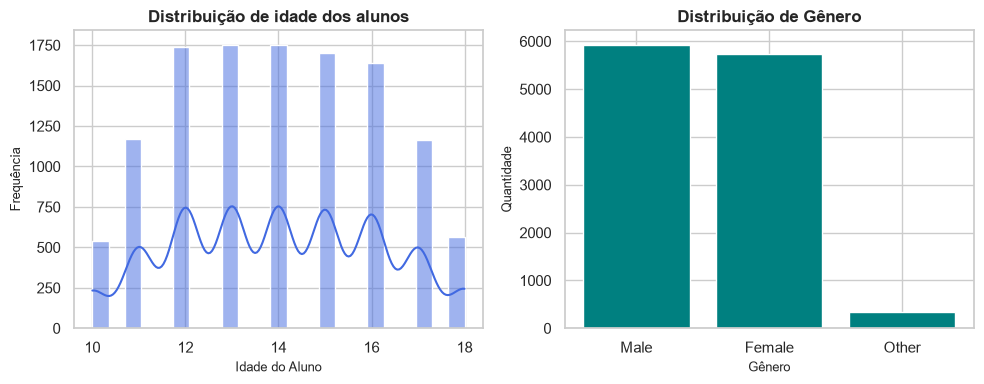

In [41]:
# Como criar uma grid de 1 linha e 2 colunas
# fig = a imagem
# ax1 e ax2 são os quadrantes
fig, (ax1, ax2) = plt.subplots(
    nrows = 1, 
    ncols = 2, 
    figsize = (10,4))
#agora vamos fazer o gráfico da esquerda, um histograma com KDE das idades
sns.histplot(
    data=df,
    x = 'age',
    kde=True,
    ax=ax1,
    color="royalblue")
#colocação o título desse gráfico
ax1.set_title(
    "Distribuição de idade dos alunos",
    fontsize = 12,
    fontweight = "bold")
# editando o título das labels
ax1.set_ylabel("Frequência", fontsize = 9)
ax1.set_xlabel("Idade do Aluno", fontsize = 9)
# agora vamos fazer o gráfico da direita, um gráfico de barras do gênero dos alunos com o % dentro das barras
#contando quantos generos tem
contagens = df['gender'].value_counts()
#Desenhando as barras no eixo ax2
barras = ax2.bar(contagens.index, contagens.values, color = "teal")
#colocando títulos
ax2.set_title("Distribuição de Gênero", fontsize=12, fontweight="bold")
ax2.set_ylabel("Quantidade", fontsize = 9)
ax2.set_xlabel("Gênero", fontsize = 9)

# Garante que títulos e rótulos não colidam nem fiquem colados nas bordas
plt.tight_layout()
plt.show()